importing all libraries 


In [197]:
from sklearn.datasets import load_breast_cancer
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import model_selection, preprocessing, metrics
import tensorflow as tf

---------------------------------------------------------------------------------------------------------------------

### Task 1: Data Loading, EDA & Preprocessing

Load the dataset --- importing dataset, defining X and Y & Checking shape, target counts and statistics.

In [198]:
df = load_breast_cancer(as_frame=True)

x = df.data
y = df.target 

print("Shape of X:", x.shape, "\n")
print("--------------------------------------------------\n")
print("Value Counts:", y.value_counts(), "\n")
print("--------------------------------------------------\n")
print("Description of X:\n", x.describe(), "\n")


Shape of X: (569, 30) 

--------------------------------------------------

Value Counts: target
1    357
0    212
Name: count, dtype: int64 

--------------------------------------------------

Description of X:
        mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.1043

---------------------------------------------------------------------------------------------------------------------

Class distribution plot --- ploting count plot and showing number of Malignant and Benign cases.

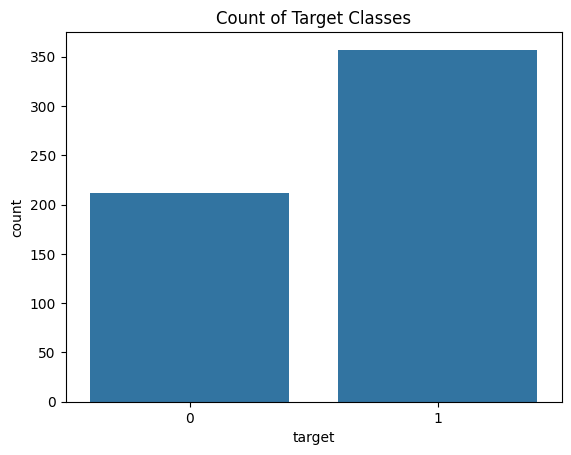

Value Counts: target
1    357
0    212
Name: count, dtype: int64 



In [199]:
sns.countplot(x=y)
plt.title("Count of Target Classes")
plt.show()

print("Value Counts:", y.value_counts(), "\n")

Short Explanation: 

The dataset contains 357 Benign cases (1) and 212 Malignant cases (0).
There is a mild class imbalance because the number of Benign cases is higher
than the number of Malignant cases. However, the imbalance is not severe for
this dataset size, so special handling is not required.

---------------------------------------------------------------------------------------------------------------------

Feature correlation heatmap

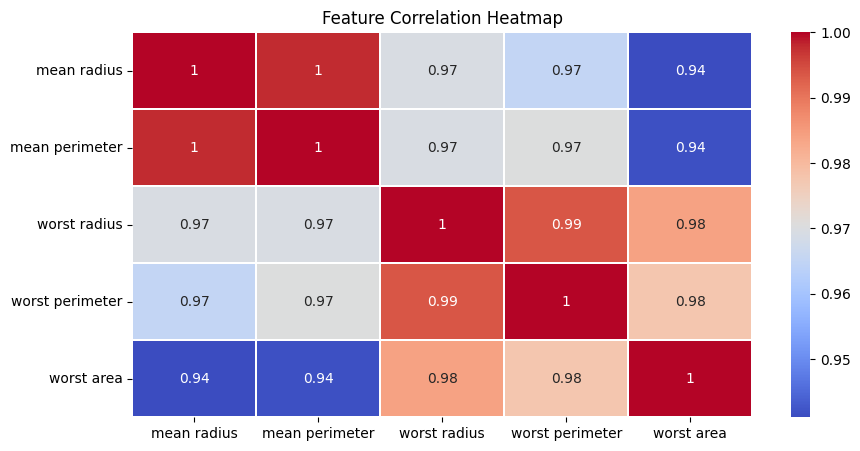

In [200]:
corr = x[['mean radius','mean perimeter','worst radius', 'worst perimeter', 'worst area']].corr()

plt.figure(figsize=(10, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=0.2)
plt.title("Feature Correlation Heatmap")
plt.show()

Unlike linear models, neural networks can learn non-linear patterns using their weight and bias and are less affected by correlated input features.

---------------------------------------------------------------------------------------------------------------------

Train / test split 

In [201]:
x_train, x_test, y_train, y_test = model_selection.train_test_split(x, y, test_size=0.2, random_state=42, stratify=y )
print("Shape of x_train:", x_train.shape, "\n")
print("Shape of y_train:", y_train.shape, "\n")
print("Shape of x_test:", x_test.shape, "\n")
print("Shape of y_test:", y_test.shape, "\n")


Shape of x_train: (455, 30) 

Shape of y_train: (455,) 

Shape of x_test: (114, 30) 

Shape of y_test: (114,) 



---------------------------------------------------------------------------------------------------------------------

Apply StandardScaler

In [202]:
scaler = preprocessing.StandardScaler()

x_train_sc = scaler.fit_transform(x_train)
x_test_sc = scaler.transform(x_test)

In [203]:
print("X_train mean:\n",x_train_sc.mean(axis=0).round(2),"\n")
print("X_train Std:\n",x_train_sc.std(axis=0).round(2))
print("--------------------------------------------------\n")
print("X_test Mean:\n",x_test_sc.mean(axis=0).round(2),"\n")
print("X_test Std:\n",x_test_sc.std(axis=0).round(2))


X_train mean:
 [-0.  0. -0. -0.  0. -0. -0.  0. -0.  0. -0. -0.  0.  0. -0. -0.  0. -0.
  0.  0.  0. -0. -0.  0.  0. -0.  0. -0. -0.  0.] 

X_train Std:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]
--------------------------------------------------

X_test Mean:
 [ 0.09  0.05  0.09  0.09  0.07  0.04 -0.02  0.07  0.1  -0.02  0.12 -0.02
  0.11  0.13 -0.07 -0.02 -0.1   0.1  -0.13 -0.    0.1   0.02  0.1   0.1
  0.01 -0.   -0.1   0.05 -0.06  0.  ] 

X_test Std:
 [1.03 0.88 1.03 1.1  1.21 0.93 0.87 0.98 0.87 0.93 1.16 0.81 1.11 1.39
 0.76 0.84 0.59 0.9  0.66 0.73 1.06 0.94 1.06 1.14 1.06 0.92 0.81 0.92
 0.76 0.9 ]


WHY scaling for neural networks

StandardScaler brings features to a similar scale by making their mean approximately 0 and standard deviation approximately 1. This prevents large-value features from making the model complex and helps model train faster and more stably.

---------------------------------------------------------------------------------------------------------------------

### Task 2: Single-Layer Perceptron (SLP) — Baseline Model

	
Build the SLP

In [204]:
model_slp = tf.keras.Sequential([
    tf.keras.layers.Dense(1, activation='sigmoid', input_shape=(30,))
    ])

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


	
Compile the SLP

In [205]:
model_slp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

	
Train the SLP

In [206]:
history_slp = model_slp.fit(x_train_sc, y_train, epochs=50, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3839 - loss: 1.0125 - val_accuracy: 0.3043 - val_loss: 1.0858
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4474 - loss: 0.9165 - val_accuracy: 0.3478 - val_loss: 0.9944
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5306 - loss: 0.8279 - val_accuracy: 0.3478 - val_loss: 0.9139
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6039 - loss: 0.7553 - val_accuracy: 0.4130 - val_loss: 0.8402
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6553 - loss: 0.6896 - val_accuracy: 0.5217 - val_loss: 0.7769
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6919 - loss: 0.6336 - val_accuracy: 0.5652 - val_loss: 0.7220
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7335 - loss: 0.5850 - val_accuracy: 0.6087 - val_loss: 0.6735
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7579 - loss: 0.5439 - val_accuracy: 0.6522 - val_loss

Plot SLP training curves

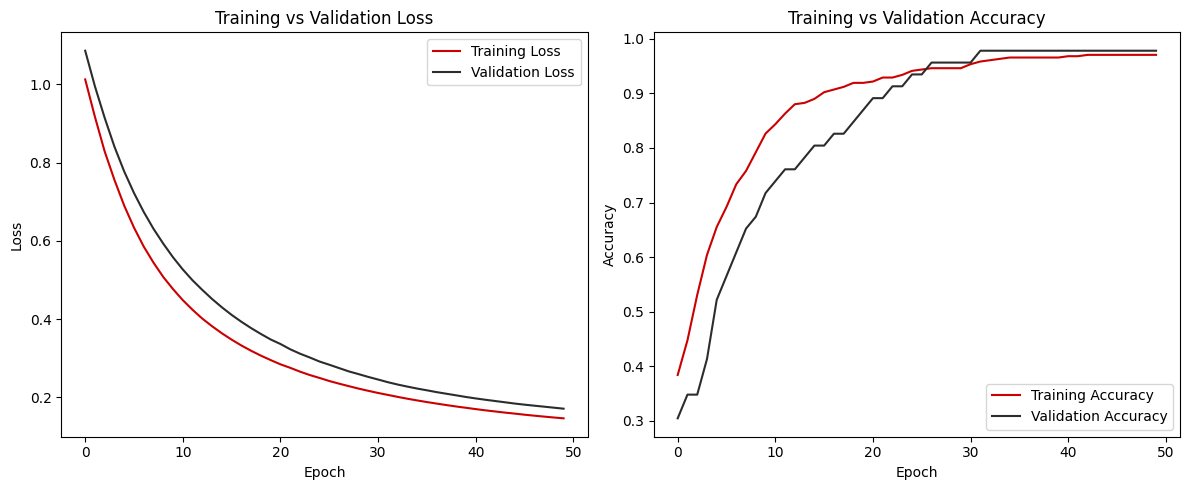

In [237]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_slp.history['loss'], label='Training Loss',color='#CC0000')
plt.plot(history_slp.history['val_loss'], label='Validation Loss',color='#2C2C2C')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_slp.history['accuracy'], label='Training Accuracy',color='#CC0000')
plt.plot(history_slp.history['val_accuracy'], label='Validation Accuracy',color='#2C2C2C')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

Training and validation loss decrease over the epochs, while accuracy increases.
The training and validation performance remain close, showing that the SLP is learning well with no major overfitting.

Evaluate the SLP

In [208]:
slp_loss, slp_acc = model_slp.evaluate(x_test_sc, y_test, verbose=0)
print(f"Accuracy: {slp_acc:.4f}")
y_pred_slp = (model_slp.predict(x_test_sc)>0.5).astype("int")

Accuracy: 0.9825
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


---------------------------------------------------------------------------------------------------------------------

In [209]:
print(metrics.classification_report(y_test, y_pred_slp))


              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



### Task 3: Multi-Layer Perceptron (MLP) — Activation Functions

---------------------------------------------------------------------------------------------------------------------

In [210]:
model_mlp = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='relu', input_shape=(30,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
    ])

model_mlp.summary()

c:\Users\Admin\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_29 (Dense)                │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

WHY hidden layers — Markdown

One feature alone may not tell us whether a tumor is malignant or benign, but a combination of several features can give a much better prediction.

---------------------------------------------------------------------------------------------------------------------

Compile and train MLP (ReLU)

In [211]:
model_mlp.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_mlp = model_mlp.fit(x_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5892 - loss: 0.6332 - val_accuracy: 0.8043 - val_loss: 0.4681
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8973 - loss: 0.3584 - val_accuracy: 0.8913 - val_loss: 0.3324
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9511 - loss: 0.2268 - val_accuracy: 0.8913 - val_loss: 0.2524
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9535 - loss: 0.1586 - val_accuracy: 0.9130 - val_loss: 0.2020
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9633 - loss: 0.1217 - val_accuracy: 0.9348 - val_loss: 0.1667
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9731 - loss: 0.1006 - val_accuracy: 0.9565 - val_loss: 0.1461
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9731 - loss: 0.0877 - val_accuracy: 0.9565 - val_loss: 0.1278
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9756 - loss: 0.0791 - val_accuracy: 0.9565 - 

In [212]:
    model_mlp_tanh = tf.keras.Sequential([
        tf.keras.layers.Dense(64, activation='tanh', input_shape=(30,)),
        tf.keras.layers.Dense(32, activation='tanh'),
        tf.keras.layers.Dense(1, activation='sigmoid')
        ])

    model_mlp_tanh.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    history_mlp_tanh = model_mlp_tanh.fit(x_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7971 - loss: 0.4837 - val_accuracy: 0.8478 - val_loss: 0.3421
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9364 - loss: 0.2156 - val_accuracy: 0.9130 - val_loss: 0.2350
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9535 - loss: 0.1405 - val_accuracy: 0.9130 - val_loss: 0.1813
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9682 - loss: 0.1082 - val_accuracy: 0.9348 - val_loss: 0.1370
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9756 - loss: 0.0892 - val_accuracy: 0.9783 - val_loss: 0.1113
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9756 - loss: 0.0774 - val_accuracy: 0.9783 - val_loss: 0.0946
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9829 - loss: 0.0706 - val_accuracy: 0.9783 - val_loss: 0.0857
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9878 - loss: 0.0654 - val_accuracy: 0.9783 - 

In [213]:
model_mlp_sigmoid = tf.keras.Sequential([
    tf.keras.layers.Dense(64, activation='tanh', input_shape=(30,)),
    tf.keras.layers.Dense(32, activation='tanh'),
    tf.keras.layers.Dense(1, activation='sigmoid')
    ])

model_mlp_sigmoid.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_mlp_sigmoid = model_mlp_sigmoid.fit(x_train_sc, y_train, epochs=100, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9022 - loss: 0.3707 - val_accuracy: 0.9348 - val_loss: 0.2336
Epoch 2/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9682 - loss: 0.1554 - val_accuracy: 0.9348 - val_loss: 0.1856
Epoch 3/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9707 - loss: 0.1108 - val_accuracy: 0.9348 - val_loss: 0.1494
Epoch 4/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9731 - loss: 0.0909 - val_accuracy: 0.9565 - val_loss: 0.1224
Epoch 5/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9756 - loss: 0.0804 - val_accuracy: 0.9565 - val_loss: 0.1020
Epoch 6/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9804 - loss: 0.0738 - val_accuracy: 0.9565 - val_loss: 0.0924
Epoch 7/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9853 - loss: 0.0690 - val_accuracy: 0.9565 - val_loss: 0.0868
Epoch 8/100
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9853 - loss: 0.0653 - val_accuracy: 0.9565 - 

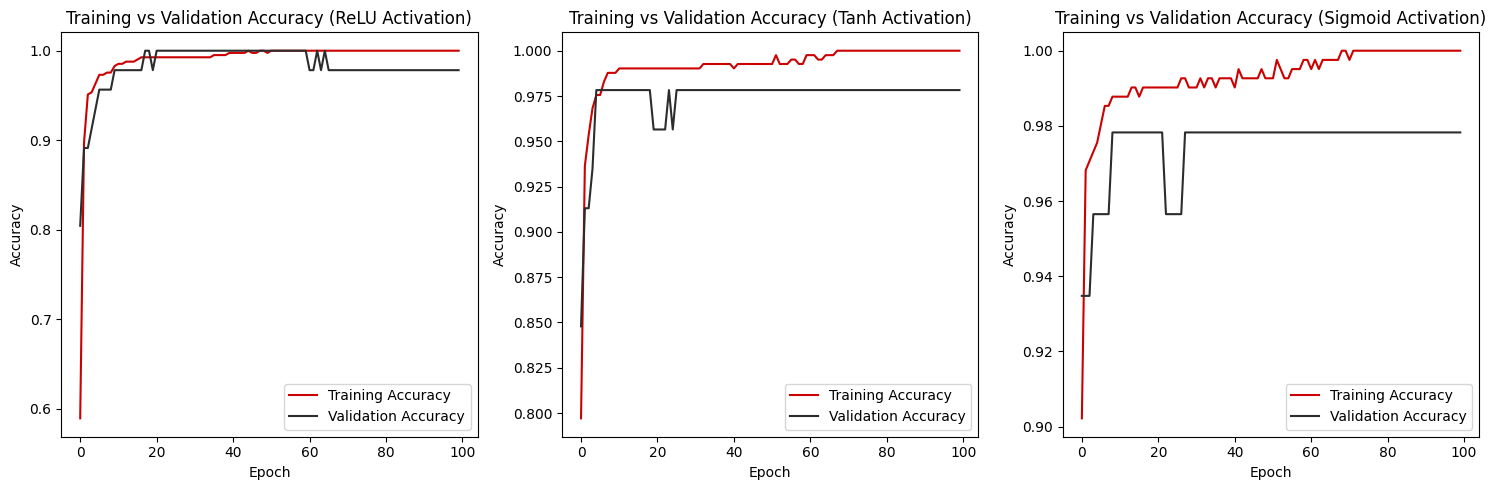

In [214]:
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)

plt.plot(history_mlp.history['accuracy'], label='Training Accuracy',color='#CC0000')
plt.plot(history_mlp.history['val_accuracy'], label='Validation Accuracy',color='#2C2C2C')

plt.title('Training vs Validation Accuracy (ReLU Activation)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 2)

plt.plot(history_mlp_tanh.history['accuracy'], label='Training Accuracy',color='#CC0000')
plt.plot(history_mlp_tanh.history['val_accuracy'], label='Validation Accuracy',color='#2C2C2C')

plt.title('Training vs Validation Accuracy (Tanh Activation)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 3, 3)

plt.plot(history_mlp_sigmoid.history['accuracy'], label='Training Accuracy',color='#CC0000')
plt.plot(history_mlp_sigmoid.history['val_accuracy'], label='Validation Accuracy',color='#2C2C2C')

plt.title('Training vs Validation Accuracy (Sigmoid Activation)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

ReLU, Tanh, and Sigmoid all achieve high training accuracy.
ReLU shows the most stable validation performance, while Tanh and Sigmoid show a larger training-validation gap.
Therefore, ReLU performs better for this MLP.

In [217]:
mlp_loss , mlp_acc = model_mlp.evaluate(x_test_sc, y_test, verbose=0)
print(f"MLP (ReLU) Accuracy: {mlp_acc:.4f}")

MLP (ReLU) Accuracy: 0.9649


In [219]:
y_pred_mlp = (model_mlp.predict(x_test_sc) > 0.5).astype("int")
print(metrics.classification_report(y_test, y_pred_mlp))

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
              precision    recall  f1-score   support

           0       0.93      0.98      0.95        42
           1       0.99      0.96      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.97      0.96       114
weighted avg       0.97      0.96      0.97       114



---------------------------------------------------------------------------------------------------------------------

### Task 4: Early Stopping



Build MLP for Early Stopping experiment

In [224]:
model_mlp_f = tf.keras.Sequential([
    tf.keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
    ])

model_mlp_f.summary()

Model: "sequential_19"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_47 (Dense)                │ (None, 128)            │         3,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

In [225]:
model_mlp_f.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_mlp_f = model_mlp_f.fit(x_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, verbose=1)

Epoch 1/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9315 - loss: 0.3857 - val_accuracy: 0.9348 - val_loss: 0.2552
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9633 - loss: 0.1707 - val_accuracy: 0.9348 - val_loss: 0.1701
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9633 - loss: 0.1076 - val_accuracy: 0.9565 - val_loss: 0.1315
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9756 - loss: 0.0852 - val_accuracy: 0.9565 - val_loss: 0.1086
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9780 - loss: 0.0712 - val_accuracy: 0.9565 - val_loss: 0.0829
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9804 - loss: 0.0636 - val_accuracy: 0.9783 - val_loss: 0.0687
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9829 - loss: 0.0576 - val_accuracy: 0.9565 - val_loss: 0.0731
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9878 - loss: 0.0501 - val_accuracy: 0.9783 - 

In [226]:
earlystop_mlp_f = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history_mlp_f_es = model_mlp_f.fit( x_train_sc, y_train, epochs=300, batch_size=32, validation_split=0.1, callbacks=[earlystop_mlp_f], verbose=1 )

Epoch 1/300


13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.2185e-05 - val_accuracy: 0.9783 - val_loss: 0.0290
Epoch 2/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.1963e-05 - val_accuracy: 0.9783 - val_loss: 0.0300
Epoch 3/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.1816e-05 - val_accuracy: 0.9783 - val_loss: 0.0294
Epoch 4/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.1692e-05 - val_accuracy: 0.9783 - val_loss: 0.0291
Epoch 5/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.1594e-05 - val_accuracy: 0.9783 - val_loss: 0.0287
Epoch 6/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.1494e-05 - val_accuracy: 0.9783 - val_loss: 0.0297
Epoch 7/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.1366e-05 - val_accuracy: 0.9783 - val_loss: 0.0296
Epoch 8/300
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 1.1225e-05 - val_

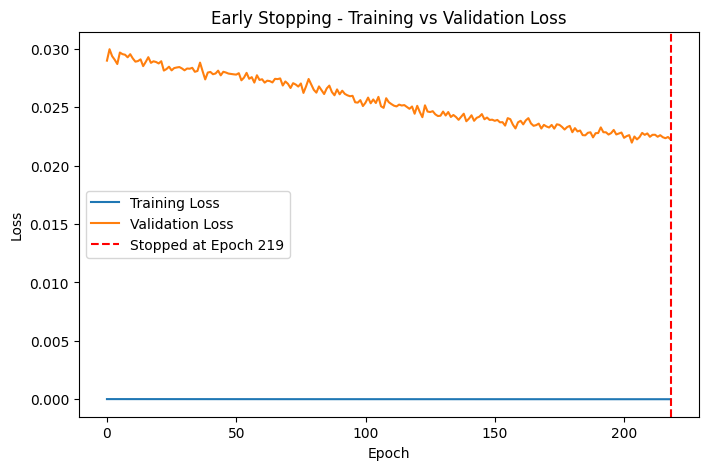

In [233]:
plt.figure(figsize=(8, 5))

plt.plot(history_mlp_f_es.history['loss'], label='Training Loss')
plt.plot(history_mlp_f_es.history['val_loss'], label='Validation Loss')

stopped_epoch = len(history_mlp_f_es.history['loss'])

plt.axvline(
    x=stopped_epoch-1,
    color='red',
    linestyle='--',
    label=f'Stopped at Epoch {stopped_epoch}'
)

plt.title('Early Stopping - Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

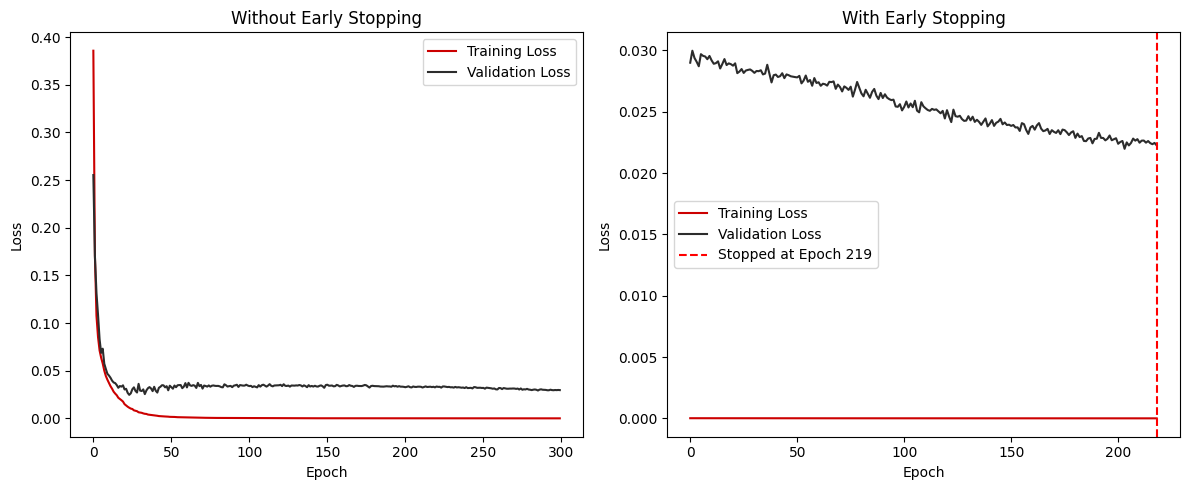

In [242]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history_mlp_f.history['loss'], label='Training Loss',color='#CC0000')
plt.plot(history_mlp_f.history['val_loss'], label='Validation Loss',color='#2C2C2C')

plt.title('Without Early Stopping')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_mlp_f_es.history['loss'], label='Training Loss',color='#CC0000')
plt.plot(history_mlp_f_es.history['val_loss'], label='Validation Loss',color='#2C2C2C')

plt.title('With Early Stopping')
plt.axvline(x=stopped_epoch-1, color='red', linestyle='--', label=f'Stopped at Epoch {stopped_epoch}')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()